In [ ]:
# Final Project: Predicting Machine Failure Using the AI4I 2020 Dataset

In [ ]:
Course: Artificial Intelligence / Machine Learning
Student: [Your name]
Dataset source: UCI Machine Learning Repository, AI4I 2020 Predictive Maintenance Dataset
Research question: Can machine operating measurements predict whether a machine will fail?

In [ ]:
Abstract

This notebook is a complete, reproducible classification experiment. 
It includes data checks, tables, seven EDA visualizations, model building, 
and evaluation. It uses only the attached dataset (ai4i2020.csv) and 
common Python libraries. All random splits are reproducible.

In [ ]:
## Table of Content

# 1.Project Introduction and Dataset Overview

# 2.Exploratory Data Analysis (EDA)
#     - Data Inspection and Data Quality
#     - Chart 1: Machine Failure Class Distribution
#     - Chart 2: Machine Product Types
#     - Chart 3: Tool Wear Distribution by Failure Status
#     - Chart 4: Rotational Speed vs. Torque
#     - Chart 5: Process Temperature Distribution
#     - Chart 6: Correlation Heatmap
#     - Chart 7: Failure Rate by Machine Type

# 3.Data Preparation and Modeling Design

# 4.Model Training and Evaluation
#     - Model Comparison
#     - Confusion Matrices and Classification Reports
#     - ROC Curves

# 5. Interpretation, Limitations, and Conclusion


In [1]:
# Libraries used throughout the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_columns", 20)
DATA_FILE = Path('ai4i2020.csv')
if not DATA_FILE.exists():
    DATA_FILE = Path('/mnt/data/ai4i2020.csv')  # Local environment fallback
assert DATA_FILE.exists(), "Place ai4i2020.csv next to this notebook before running."
df = pd.read_csv(DATA_FILE)
print('Dataset shape:', df.shape)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print('Column types:')
print(df.dtypes.to_string())
print('\nMissing values by column:')
print(df.isna().sum().to_string())
print('\nExact duplicated rows:', df.duplicated().sum())
display(df.describe(include='all').T)
counts = df['Machine failure'].value_counts().sort_index()
print('\nFailure counts:', counts.to_dict())
print('Failure percentage:', round(100 * df['Machine failure'].mean(), 2), '%')

Column types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64

Missing values by column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0

Exact duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0



Failure counts: {0: 9661, 1: 339}
Failure percentage: 3.39 %


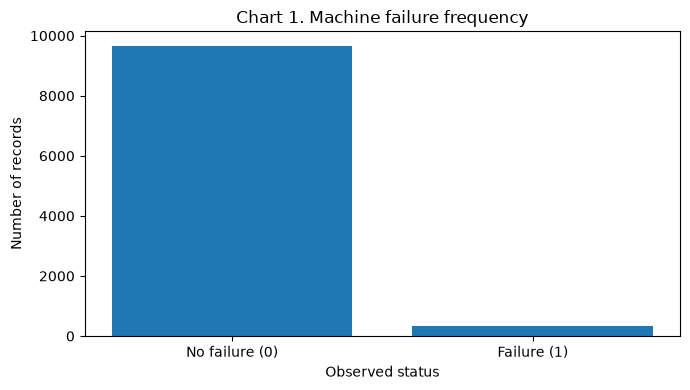

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['No failure (0)', 'Failure (1)'], df['Machine failure'].value_counts().sort_index().values)
ax.set_title('Chart 1. Machine failure frequency')
ax.set_xlabel('Observed status'); ax.set_ylabel('Number of records')
plt.tight_layout(); plt.show()

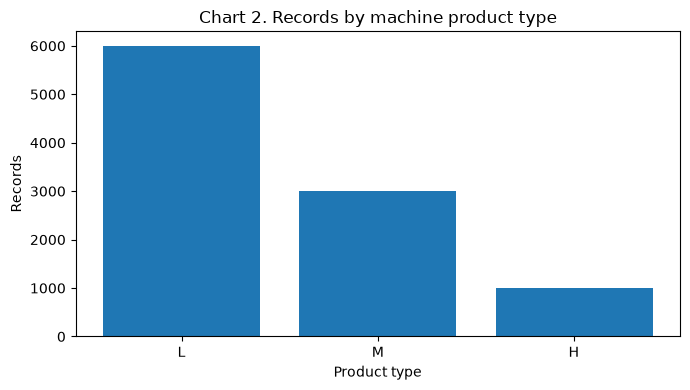

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['L','M','H'], df['Type'].value_counts().reindex(['L','M','H']).values)
ax.set_title('Chart 2. Records by machine product type')
ax.set_xlabel('Product type'); ax.set_ylabel('Records')
plt.tight_layout(); plt.show()

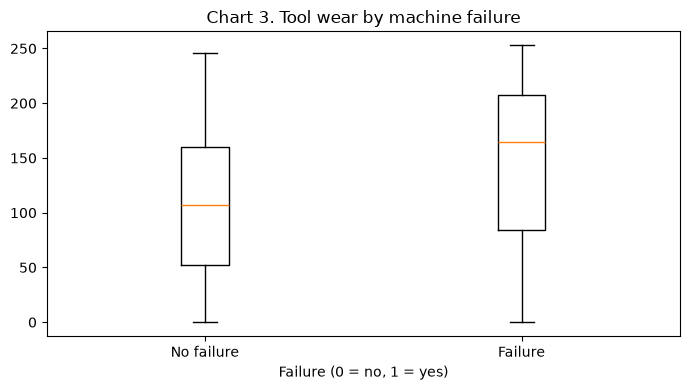

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
ax.boxplot([df.loc[df['Machine failure']==0,'Tool wear [min]'], df.loc[df['Machine failure']==1,'Tool wear [min]']], tick_labels=['No failure','Failure'])
ax.set_title('Chart 3. Tool wear by machine failure')
ax.set_xlabel('Failure (0 = no, 1 = yes)')
plt.tight_layout(); plt.show()

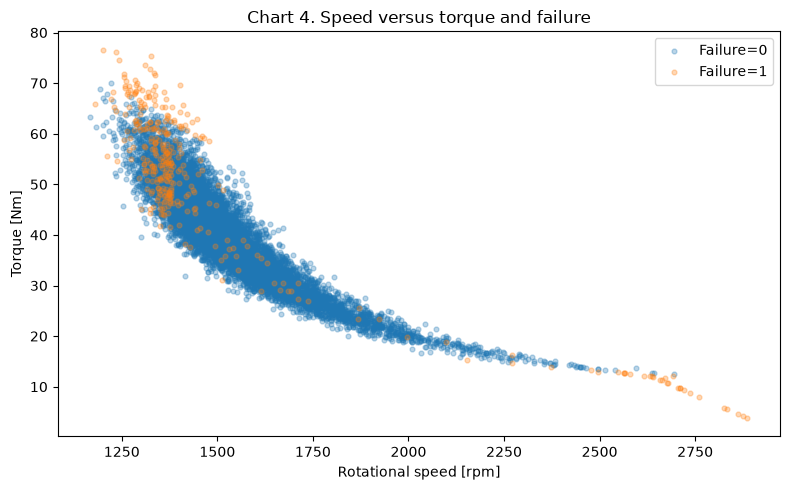

In [6]:
fig, ax = plt.subplots(figsize=(8,5))

for status, group in df.groupby('Machine failure'):
    ax.scatter(group['Rotational speed [rpm]'], group['Torque [Nm]'], alpha=.3, s=12, label=f'Failure={status}')
ax.set_xlabel('Rotational speed [rpm]'); ax.set_ylabel('Torque [Nm]'); ax.legend()
ax.set_title('Chart 4. Speed versus torque and failure')
plt.tight_layout(); plt.show()

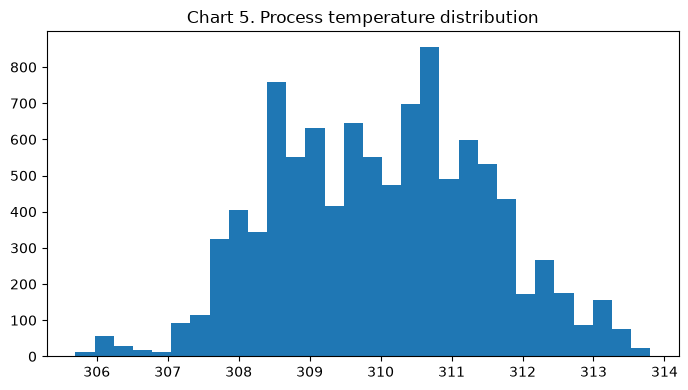

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df['Process temperature [K]'],bins=30)
ax.set_title('Chart 5. Process temperature distribution')
plt.tight_layout(); plt.show()

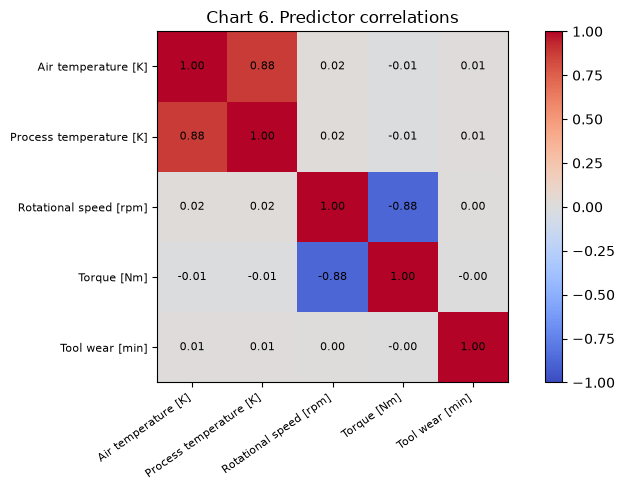

In [8]:
numeric_predictors=['Air temperature [K]', 'Process temperature [K]',
                    'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, ax = plt.subplots(figsize=(8,5))

corr=df[numeric_predictors].corr().values
im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(5),numeric_predictors,rotation=35,ha='right',fontsize=8)
ax.set_yticks(range(5),numeric_predictors,fontsize=8)
for i in range(5):
    for j in range(5):ax.text(j,i,f'{corr[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax)
ax.set_title('Chart 6. Predictor correlations')
plt.tight_layout(); plt.show()

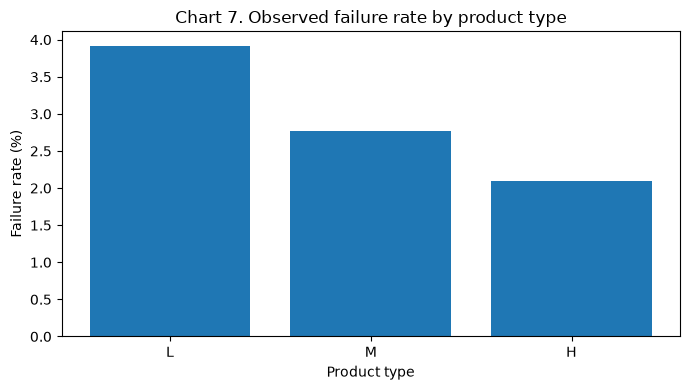

Observed failure rate by type (%):
Type
L    3.92
M    2.77
H    2.09


In [9]:
rates=100*df.groupby('Type')['Machine failure'].mean().reindex(['L','M','H'])
fig, ax=plt.subplots(figsize=(7,4))
ax.bar(rates.index, rates.values)
ax.set_title('Chart 7. Observed failure rate by product type')
ax.set_xlabel('Product type'); ax.set_ylabel('Failure rate (%)')
plt.tight_layout(); plt.show()
print('Observed failure rate by type (%):')
print(rates.round(2).to_string())

In [10]:
feature_cols=['Type'] + numeric_predictors
target='Machine failure'
X=df[feature_cols].copy()
y=df[target].astype(int)
X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print('Train rows:',len(X_train),'Test rows:',len(X_test))
print('Train class counts:', y_train.value_counts().sort_index().to_dict())
print('Test class counts:', y_test.value_counts().sort_index().to_dict())

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric_predictors),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Type'])
    ])

models={
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10,
                                            class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=3,
                                            class_weight='balanced', random_state=42, n_jobs=-1)
}


Train rows: 8000 Test rows: 2000
Train class counts: {0: 7729, 1: 271}
Test class counts: {0: 1932, 1: 68}


In [11]:
results=[]
fitted={}
for name, estimator in models.items():
    pipe=Pipeline([('prepare',make_preprocessor()),('model',estimator)])
    pipe.fit(X_train, y_train)
    pred=pipe.predict(X_test)
    probability=pipe.predict_proba(X_test)[:,1]
    fitted[name]=pipe
    results.append({'Model':name,
        'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0),
        'F1':f1_score(y_test,pred,zero_division=0),
        'ROC-AUC':roc_auc_score(y_test,probability)})
results_df=pd.DataFrame(results).sort_values('F1',ascending=False).reset_index(drop=True)
print('Test-set evaluation table:')
display(results_df.round(4))
best_name=results_df.iloc[0]['Model']
print('Best model on this held-out test set by F1:',best_name)
print('Important: this is an exploratory comparison, not an independently validated production model.')

Test-set evaluation table:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.9655,0.4954,0.7941,0.6102,0.9712
1,Decision Tree,0.9320,0.3152,0.8529,0.4603,0.8789
2,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070


Best model on this held-out test set by F1: Random Forest
Important: this is an exploratory comparison, not an independently validated production model.



 Logistic Regression
              precision    recall  f1-score   support

  No failure       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



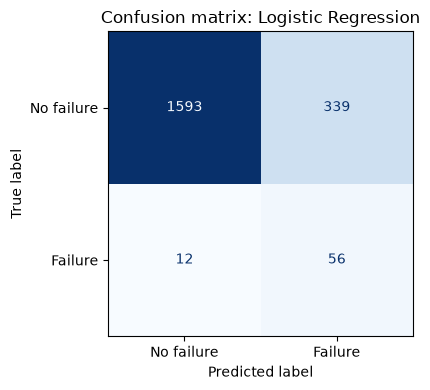


 Decision Tree
              precision    recall  f1-score   support

  No failure       0.99      0.93      0.96      1932
     Failure       0.32      0.85      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.89      0.71      2000
weighted avg       0.97      0.93      0.95      2000



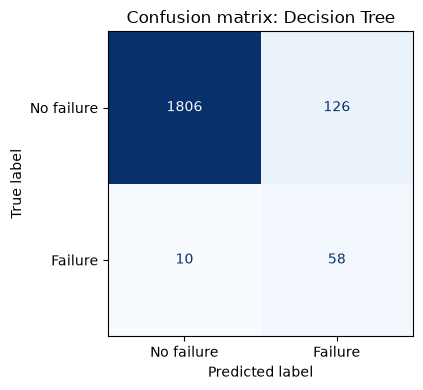


 Random Forest
              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      1932
     Failure       0.50      0.79      0.61        68

    accuracy                           0.97      2000
   macro avg       0.74      0.88      0.80      2000
weighted avg       0.98      0.97      0.97      2000



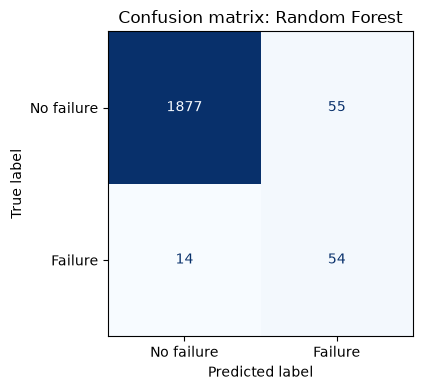

In [12]:
for name, model in fitted.items():
    print('\n',name)
    predicted=model.predict(X_test)
    print(classification_report(y_test,predicted,target_names=['No failure','Failure'],zero_division=0))
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay.from_predictions(y_test,predicted,display_labels=['No failure','Failure'],
                                            cmap='Blues',ax=ax,colorbar=False)
    ax.set_title(f'Confusion matrix: {name}')
    plt.tight_layout();plt.show()

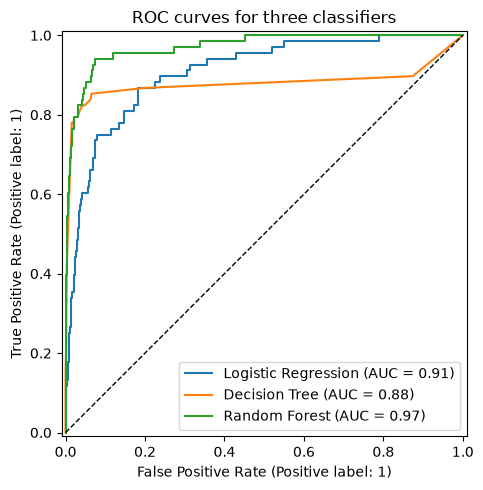

In [13]:
fig,ax=plt.subplots(figsize=(7,5))
for name,model in fitted.items():
    RocCurveDisplay.from_estimator(model,X_test,y_test,ax=ax,name=name)
ax.plot([0,1],[0,1],'k--',linewidth=1,label='Chance')
ax.set_title('ROC curves for three classifiers')
plt.tight_layout();plt.show()